(6, 3)
(18,)
[ 0.          0.04008016  0.08016032  0.12024048  0.16032064  0.2004008
  0.24048096  0.28056112  0.32064128  0.36072144  0.4008016   0.44088176
  0.48096192  0.52104208  0.56112224  0.6012024   0.64128257  0.68136273
  0.72144289  0.76152305  0.80160321  0.84168337  0.88176353  0.92184369
  0.96192385  1.00200401  1.04208417  1.08216433  1.12224449  1.16232465
  1.20240481  1.24248497  1.28256513  1.32264529  1.36272545  1.40280561
  1.44288577  1.48296593  1.52304609  1.56312625  1.60320641  1.64328657
  1.68336673  1.72344689  1.76352705  1.80360721  1.84368737  1.88376754
  1.9238477   1.96392786  2.00400802  2.04408818  2.08416834  2.1242485
  2.16432866  2.20440882  2.24448898  2.28456914  2.3246493   2.36472946
  2.40480962  2.44488978  2.48496994  2.5250501   2.56513026  2.60521042
  2.64529058  2.68537074  2.7254509   2.76553106  2.80561122  2.84569138
  2.88577154  2.9258517   2.96593186  3.00601202  3.04609218  3.08617234
  3.12625251  3.16633267  3.20641283  3.

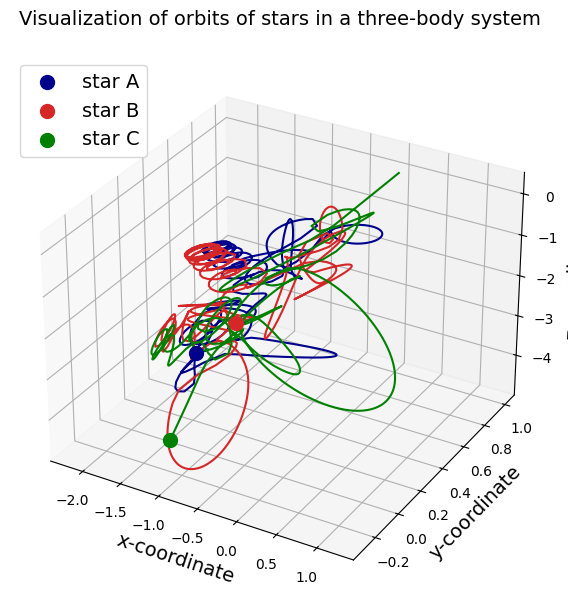

In [13]:
import scipy as sci
import matplotlib.pyplot as plt
import mpl_toolkits.mplot3d.axes3d as p3
import matplotlib.animation as animation
import numpy as numpy
import scipy.integrate

# Define universal gravitation constant
G = 6.67408e-11  # N-m2/kg2
# Reference quantities
m_nd = 1.989e+30  # kg #mass of the sun
r_nd = 5.326e+12  # m #distance between stars in Alpha Centauri
v_nd = 30000  # m/s #relative velocity of earth around the sun
t_nd = 79.91 * 365 * 24 * 3600 * 0.51  # s #orbital period of Alpha Centauri
# Net constants
K1 = G * t_nd * m_nd / (r_nd ** 2 * v_nd)
K2 = v_nd * t_nd / r_nd

# Define masses
m1 = 1.1  # star A
m2 = 0.907  # star B
m3 = 1.0 # star C
# Define initial position vectors
r1 = [-0.5, 0, 0]  # m
r2 = [0.5, 0, 0]  # m
r3 = [0, 1, 0] # m
# Convert pos vectors to arrays
r1 = numpy.array(r1, dtype="float64")
r2 = numpy.array(r2, dtype="float64")
r3=numpy.array(r3,dtype="float64")
# Define initial velocities
v1 = [0.01, 0.01, 0]  # m/s
v2 = [-0.05, 0, -0.1]  # m/s
v3 = [0, -0.01, 0] # m/s
# Convert velocity vectors to arrays
v1 = numpy.array(v1, dtype="float64")
v2 = numpy.array(v2, dtype="float64")
v3 = numpy.array(v3,dtype="float64")
# Find velocity of center of mass
v_com=(m1*v1+m2*v2+m3*v3)/(m1+m2+m3)
#Find location of center of mass
r_com=(m1*r1+m2*r2+m3*r3)/(m1+m2+m3)

pt_tot = 500
t_tot = 20

def ThreeBodyEquations(w, t):
    r1 = w[:3]
    r2 = w[3:6]
    r3 = w[6:9]
    v1 = w[9:12]
    v2 = w[12:15]
    v3 = w[15:18]
    r12 = sci.linalg.norm(r2 - r1)
    r13 = sci.linalg.norm(r3 - r1)
    r23 = sci.linalg.norm(r3 - r2)

    dv1bydt = K1 * m2 * (r2 - r1) / r12 ** 3 + K1 * m3 * (r3 - r1) / r13 ** 3
    dv2bydt = K1 * m1 * (r1 - r2) / r12 ** 3 + K1 * m3 * (r3 - r2) / r23 ** 3
    dv3bydt = K1 * m1 * (r1 - r3) / r13 ** 3 + K1 * m2 * (r2 - r3) / r23 ** 3
    dr1bydt = K2 * v1
    dr2bydt = K2 * v2 
    dr3bydt = K2 * v3
    r12_derivs = numpy.concatenate((dr1bydt, dr2bydt))
    r_derivs = numpy.concatenate((r12_derivs, dr3bydt))
    v12_derivs = numpy.concatenate((dv1bydt, dv2bydt))
    v_derivs = numpy.concatenate((v12_derivs, dv3bydt))
    derivs = numpy.concatenate((r_derivs, v_derivs))
    return derivs

#Package initial parameters
init_params=numpy.array([r1,r2,r3,v1,v2,v3]) #Initial parameters
print(init_params.shape)

init_params=init_params.flatten() #Flatten to make 1D array
print(init_params.shape)

time_span=numpy.linspace(0,t_tot,pt_tot) #t_tot orbital periods and pt_tot points
print(time_span)

#Run the ODE solver
three_body_sol=sci.integrate.odeint(ThreeBodyEquations,init_params,time_span)

print(three_body_sol.shape)

r1_sol=three_body_sol[:,:3]
r2_sol=three_body_sol[:,3:6]
r3_sol=three_body_sol[:,6:9]

### Create figure
fig = plt.figure(figsize=(7, 7))
# Create 3D axes
ax = fig.add_subplot(111, projection="3d")
# Plot the orbits
ax.plot(r1_sol[:, 0], r1_sol[:, 1], r1_sol[:, 2], color="darkblue")
ax.plot(r2_sol[:, 0], r2_sol[:, 1], r2_sol[:, 2], color="tab:red")
ax.plot(r3_sol[:, 0], r3_sol[:, 1], r3_sol[:, 2], color="green")
# Plot the final positions of the stars
ax.scatter(r1_sol[-1, 0], r1_sol[-1, 1], r1_sol[-1, 2], color="darkblue", marker="o", s=100, label="star A")
ax.scatter(r2_sol[-1, 0], r2_sol[-1, 1], r2_sol[-1, 2], color="tab:red", marker="o", s=100, label="star B")
ax.scatter(r3_sol[-1, 0], r3_sol[-1, 1], r3_sol[-1, 2], color="green", marker="o", s=100, label="star C")
# Add a few more bells and whistles
ax.set_xlabel("x-coordinate", fontsize=14)
ax.set_ylabel("y-coordinate", fontsize=14)
ax.set_zlabel("z-coordinate", fontsize=14)
ax.set_title("Visualization of orbits of stars in a three-body system\n", fontsize=14)
ax.legend(loc="upper left", fontsize=14)

plt.show()

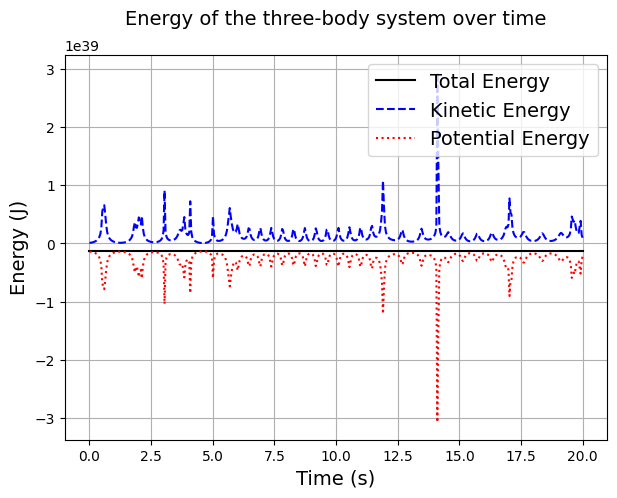

In [ ]:
v1_sol = three_body_sol[:, 9:12]
v2_sol = three_body_sol[:, 12:15]
v3_sol = three_body_sol[:, 15:18]

G3=G*m_nd**2/r_nd
G4=m_nd*(v_nd**2)

# calculate energy
def calculate_energy(r1, r2, r3, v1, v2, v3):
    # Calculate kinetic energy
    KE = G4*0.5 * (m1 * numpy.linalg.norm(v1) ** 2 + m2 * numpy.linalg.norm(v2) ** 2 + m3 * numpy.linalg.norm(v3) ** 2)
    # Calculate potential energy
    PE = -G3 * (m1 * m2 / numpy.linalg.norm(r1 - r2) + m1 * m3 / numpy.linalg.norm(r1 - r3) + m2 * m3 / numpy.linalg.norm(r2 - r3))
    return KE + PE, KE, PE

# Calculate energy at each time step
energy = []
KE = []
PE = []
for i in range(len(time_span)):
    energy_result= calculate_energy(r1_sol[i], r2_sol[i], r3_sol[i], v1_sol[i], v2_sol[i], v3_sol[i])
    energy.append(energy_result[0])
    KE.append(energy_result[1])
    PE.append(energy_result[2])
    # energy.append(calculate_energy(r1_sol[i], r2_sol[i], r3_sol[i], v1_sol[i], v2_sol[i], v3_sol[i])[0])

# Convert energy to numpy array
energy = numpy.array(energy)
# Plot energy over time
plt.figure(figsize=(7, 5))
plt.plot(time_span, energy, color="black")
plt.plot(time_span, KE, color="blue", linestyle="dashed")
plt.plot(time_span, PE, color="red", linestyle="dotted")
plt.xlabel("Time (s)", fontsize=14)
plt.ylabel("Energy (J)", fontsize=14)
plt.title("Energy of the three-body system over time\n", fontsize=14)
plt.grid()
plt.legend(["Total Energy", "Kinetic Energy", "Potential Energy"], loc="upper right", fontsize=14)
plt.show()

In [12]:
import numpy
def function():
    print("hi")

def function2():
    x=1+3
    return(x)

def function3(x):
    return x**2

def function4(x,y):
    magnitude = numpy.sqrt(x**2 + y**2)
    return magnitude

pos1=[1,2]
pos2=[3,4]

#function4(pos1[0],pos1[1])
result = function4(pos1[0],pos1[1])
print(result)

2.23606797749979
